In [1]:

# ==========================================
# TIDE: Transformation-Invariant Detection Engine
# Experiment 01: Dataset Exploration
# ==========================================

import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

DATA_DIR = "../data"

train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
unlabeled = pd.read_csv(os.path.join(DATA_DIR, "unlabeled.csv"))
test = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
starter = pd.read_csv(os.path.join(DATA_DIR, "train_starter_2000.csv"))

print("All datasets loaded successfully.")
print("Train:", train.shape)
print("Unlabeled:", unlabeled.shape)
print("Test:", test.shape)
print("Starter:", starter.shape)


All datasets loaded successfully.
Train: (10000, 3)
Unlabeled: (3000, 2)
Test: (3000, 2)
Starter: (2000, 3)


In [72]:

# Check dataset structure
print("\nTRAIN INFO")
print(train.info())

print("\nMISSING VALUES")
print(train.isnull().sum())

print("\nLABEL DISTRIBUTION")
print(train["label"].value_counts())

print("\nLabel proportions:")
print(train["label"].value_counts(normalize=True))

print("\nDUPLICATE IDS:", train["id"].duplicated().sum())
print("DUPLICATE TEXTS:", train["text"].duplicated().sum())

# Passage lengths
train["word_count"] = train["text"].fillna("").apply(
    lambda x: len(x.split())
)

print("\nWORD COUNT STATISTICS")
print(train.groupby("label")["word_count"].describe())

# Check starter subset overlap
print("\nSTARTER OVERLAP")
print("Starter IDs found in train:",
      starter["id"].isin(train["id"]).sum())



TRAIN INFO
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   id      10000 non-null  int64
 1   text    10000 non-null  str  
 2   label   10000 non-null  int64
dtypes: int64(2), str(1)
memory usage: 12.3 MB
None

MISSING VALUES
id       0
text     0
label    0
dtype: int64

LABEL DISTRIBUTION
label
0    5000
1    5000
Name: count, dtype: int64

Label proportions:
label
0    0.5
1    0.5
Name: proportion, dtype: float64

DUPLICATE IDS: 0
DUPLICATE TEXTS: 0

WORD COUNT STATISTICS
        count      mean        std   min    25%    50%    75%    max
label                                                               
0      5000.0  209.0452  55.065056  75.0  166.0  204.0  250.0  350.0
1      5000.0  208.3722  69.479366  75.0  151.0  209.0  262.0  350.0

STARTER OVERLAP
Starter IDs found in train: 2000


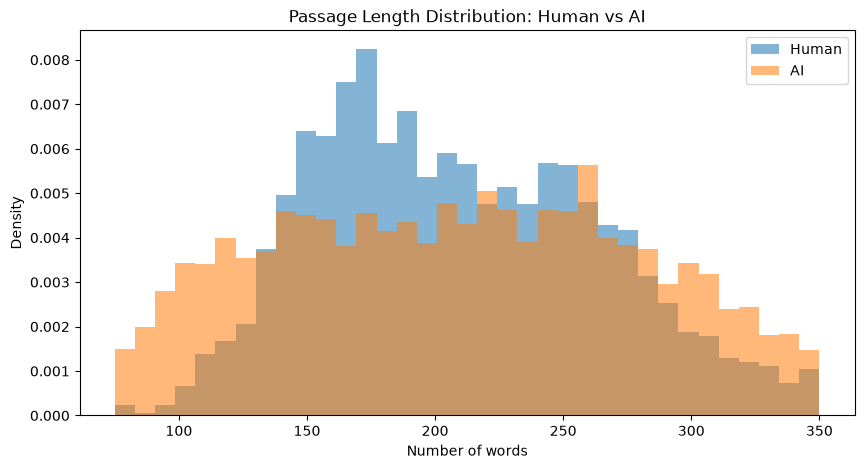

In [73]:

# Plooting passage length distributions
plt.figure(figsize=(10, 5))

for label, name in [(0, "Human"), (1, "AI")]:
    values = train.loc[
        train["label"] == label, "word_count"
    ]
    plt.hist(
        values,
        bins=35,
        alpha=0.55,
        density=True,
        label=name
    )

plt.xlabel("Number of words")
plt.ylabel("Density")
plt.title("Passage Length Distribution: Human vs AI")
plt.legend()
plt.show()


There was a significant difference between the passage length generated by human, as compared to that of AI 

In [74]:

# Create linguistic features
# Note : AI was used to check the features, but the code was written by me. The features are based on the following paper: https://arxiv.org/pdf/2305.17188.pdf 

def extract_basic_features(text):
    text = str(text)

    words = re.findall(r"\b\w+\b", text.lower())
    sentences = [
        s.strip() for s in re.split(r"[.!?]+", text)
        if s.strip()
    ]

    word_count = len(words)

    return {
        "word_count": word_count,
        "unique_word_ratio": len(set(words)) / max(word_count, 1),
        "avg_word_length": np.mean([len(w) for w in words]) if words else 0,
        "sentence_count": len(sentences),
        "avg_sentence_length": word_count / max(len(sentences), 1),
        "sentence_length_std": np.std([len(s.split()) for s in sentences]) if sentences else 0,
        "comma_ratio": text.count(",") / max(word_count, 1),
        "semicolon_ratio": text.count(";") / max(word_count, 1),
        "question_ratio": text.count("?") / max(word_count, 1),
        "exclamation_ratio": text.count("!") / max(word_count, 1),
        "parenthesis_ratio": (text.count("(") + text.count(")")) / max(word_count, 1)
    }


features = pd.DataFrame(
    train["text"].fillna("").apply(extract_basic_features).tolist()
)

features["label"] = train["label"].values

print("Feature extraction complete!")
print("Feature matrix:", features.shape)
display(features.head())


Feature extraction complete!
Feature matrix: (10000, 12)


,word_count,unique_word_ratio,avg_word_length,sentence_count,avg_sentence_length,sentence_length_std,comma_ratio,semicolon_ratio,question_ratio,exclamation_ratio,parenthesis_ratio,label
0,184,0.603261,4.619565,16,11.5000,11.126931,0.103261,0.000000,0.000000,0.0,0.021739,0
1,162,0.611111,3.672840,9,18.0000,8.445906,0.000000,0.000000,0.000000,0.0,0.000000,0
2,246,0.093496,5.077236,1,246.0000,0.000000,0.268293,0.000000,0.000000,0.0,0.008130,1
3,347,0.916427,6.818444,8,43.3750,27.918408,0.014409,0.002882,0.005764,0.0,0.000000,1
4,225,0.644444,4.884444,16,14.0625,7.774156,0.040000,0.000000,0.000000,0.0,0.008889,0


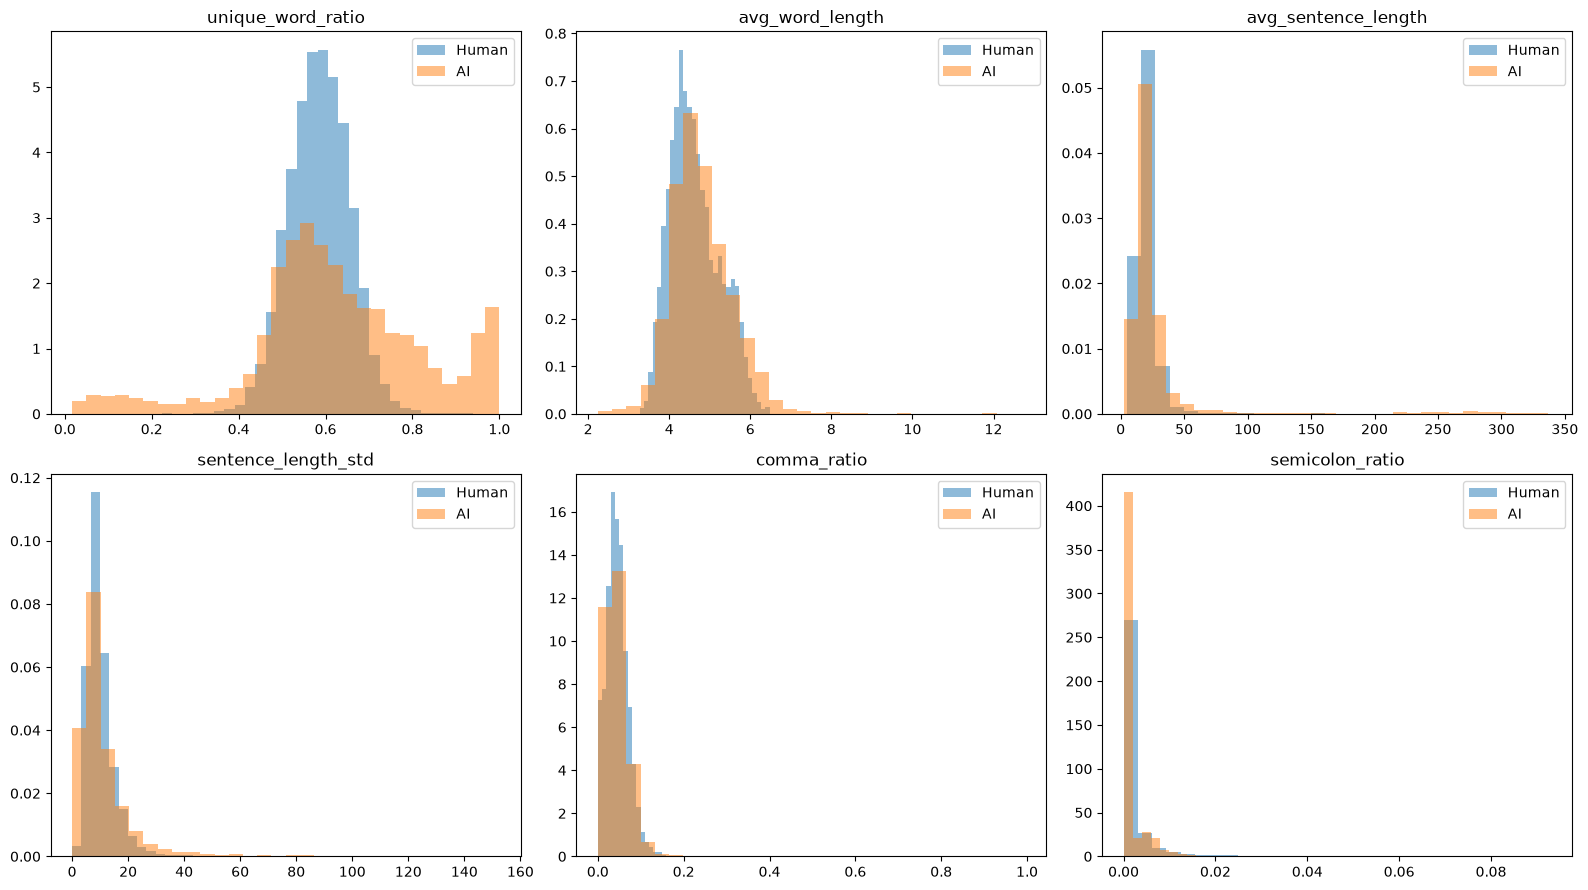

In [75]:
# plotting the significant features, chosen on the basis of above test.

features_to_plot = [
    "unique_word_ratio",
    "avg_word_length",
    "avg_sentence_length",
    "sentence_length_std",
    "comma_ratio",
    "semicolon_ratio"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(features_to_plot, axes.flatten()):
    for label, name in [(0, "Human"), (1, "AI")]:
        ax.hist(
            features.loc[features["label"] == label, feature],
            bins=30,
            alpha=0.5,
            density=True,
            label=name
        )

    ax.set_title(feature)
    ax.legend()

plt.tight_layout()
plt.show()


In [76]:
# checking the statistical significance of the features
# note :  AI was used to check the parameters, code was written by me.

from scipy.stats import mannwhitneyu, ks_2samp
from sklearn.metrics import roc_auc_score

results = []

feature_columns = [
    c for c in features.columns if c != "label"
]

y = features["label"].values

for col in feature_columns:
    human = features.loc[features["label"] == 0, col]
    ai = features.loc[features["label"] == 1, col]

    # Individual feature discrimination
    auc = roc_auc_score(y, features[col])
    
    # Direction-independent separation
    auc_strength = max(auc, 1 - auc)

    # Distribution difference
    ks_stat, ks_p = ks_2samp(human, ai)

    # Nonparametric difference in distributions
    mw_stat, mw_p = mannwhitneyu(
        human, ai, alternative="two-sided"
    )

    results.append({
        "feature": col,
        "human_mean": human.mean(),
        "ai_mean": ai.mean(),
        "human_median": human.median(),
        "ai_median": ai.median(),
        "raw_auc": auc,
        "auc_strength": auc_strength,
        "ks_statistic": ks_stat,
        "ks_p_value": ks_p
    })

feature_results = pd.DataFrame(results)

feature_results = feature_results.sort_values(
    "auc_strength", ascending=False
)

display(feature_results.round(5))


,feature,human_mean,ai_mean,human_median,ai_median,raw_auc,auc_strength,ks_statistic,ks_p_value
9,exclamation_ratio,0.00037,0.00228,0.00000,0.00000,0.60118,0.60118,0.2000,0.00000
1,unique_word_ratio,0.58557,0.62347,0.58571,0.60886,0.57008,0.57008,0.2866,0.00000
2,avg_word_length,4.63394,4.81092,4.53860,4.70550,0.56970,0.56970,0.1048,0.00000
5,sentence_length_std,10.37799,11.97945,9.00099,8.06545,0.44844,0.55156,0.1594,0.00000
3,sentence_count,11.82860,11.61360,11.00000,10.00000,0.45179,0.54821,0.1462,0.00000
4,avg_sentence_length,21.22211,29.59387,19.29706,20.10000,0.52938,0.52938,0.0892,0.00000
6,comma_ratio,0.04560,0.04417,0.04320,0.04172,0.47084,0.52916,0.0686,0.00000
10,parenthesis_ratio,0.01357,0.01473,0.00758,0.00816,0.50865,0.50865,0.0420,0.00029
8,question_ratio,0.00134,0.00179,0.00000,0.00000,0.50734,0.50734,0.0284,0.03544
7,semicolon_ratio,0.00149,0.00133,0.00000,0.00000,0.50641,0.50641,0.0176,0.42096


In [77]:

# ==========================================
# EXPERIMENT 02: FEATURE-BASED CLASSIFIERS
# ==========================================

# Note : AI was used to check the possible methods 

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

X = features.drop(columns=["label"])
y = features["label"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            C=0.1,
            max_iter=2000,
            class_weight="balanced"
        ))
    ]),

    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=400,
            max_depth=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ]),

    "Extra Trees": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", ExtraTreesClassifier(
            n_estimators=400,
            max_depth=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])
}

baseline_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    baseline_results.append({
        "Model": name,
        "Mean AUROC": scores.mean(),
        "Std AUROC": scores.std(),
        "Fold Scores": np.round(scores, 4).tolist()
    })

baseline_results = pd.DataFrame(baseline_results)

display(baseline_results)


,Model,Mean AUROC,Std AUROC,Fold Scores
0,Logistic Regression,0.690842,0.005838,"[0.6974, 0.6813, 0.6952, 0.6931, 0.6872]"
1,Random Forest,0.888578,0.005745,"[0.8781, 0.8877, 0.8898, 0.8944, 0.8929]"
2,Extra Trees,0.873011,0.003385,"[0.8686, 0.8753, 0.8693, 0.8752, 0.8767]"


Random Forest Outperforms all the existing methods 

In [78]:

from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer

# Separate features and labels
X = features.drop(columns=["label"])
y = features["label"]

# Hold out 20% of data
X_train, X_val, y_train, y_val = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Train model
rf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", RandomForestClassifier(
        n_estimators=500,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(X_train, y_train)

# Validation score
from sklearn.metrics import roc_auc_score

val_probs = rf.predict_proba(X_val)[:, 1]

print("Validation AUROC:",
      round(roc_auc_score(y_val, val_probs), 5))

# Permutation importance
importance = permutation_importance(
    rf,
    X_val,
    y_val,
    scoring="roc_auc",
    n_repeats=15,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance_mean": importance.importances_mean,
    "importance_std": importance.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance_df.round(5))


Validation AUROC: 0.88555


,feature,importance_mean,importance_std
1,unique_word_ratio,0.16492,0.00807
5,sentence_length_std,0.06912,0.00383
0,word_count,0.04719,0.00413
9,exclamation_ratio,0.04155,0.00448
6,comma_ratio,0.01993,0.00199
4,avg_sentence_length,0.01813,0.00242
2,avg_word_length,0.01364,0.00169
10,parenthesis_ratio,0.00660,0.00070
3,sentence_count,0.00543,0.00128
7,semicolon_ratio,0.00394,0.00090


Unique word ratio plays a significant role in AUROC 

In [79]:
# Ablation Study
# Here, tried experimenting with varios feature groups to see how the model performs with different subsets of features.

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

X = features.drop(columns=["label"])
y = features["label"]

top_features = [
    "unique_word_ratio",
    "sentence_length_std",
    "word_count"
]

feature_groups = {
    "Full features": list(X.columns),

    "Without unique word ratio": [
        c for c in X.columns
        if c != "unique_word_ratio"
    ],

    "Without top 3": [
        c for c in X.columns
        if c not in top_features
    ],

    "Top 3 only": top_features,

    "Remaining features": [
        c for c in X.columns
        if c not in top_features
    ]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

ablation_results = []

for group_name, selected_features in feature_groups.items():

    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(
            n_estimators=400,
            max_depth=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        model,
        X[selected_features],
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    ablation_results.append({
        "Feature Group": group_name,
        "Mean AUROC": scores.mean(),
        "Std": scores.std()
    })

ablation_df = pd.DataFrame(ablation_results)

display(
    ablation_df.sort_values(
        "Mean AUROC",
        ascending=False
    ).round(5)
)



,Feature Group,Mean AUROC,Std
0,Full features,0.88858,0.00574
1,Without unique word ratio,0.84192,0.00456
3,Top 3 only,0.82674,0.00978
2,Without top 3,0.80219,0.00333
4,Remaining features,0.80219,0.00333


Conclusion : Including all the feature produces best accuracy

Experiment : Adding MATTR Data 

MATTR (Moving-Average Type-Token Ratio) measures how varied the vocabulary is by calculating word diversity across fixed-length text segments.

Note : This idea came busing AI

In [43]:

def calculate_mattr(text, window_size=50):
    words = re.findall(r"\b\w+\b", str(text).lower())

    if len(words) < window_size:
        return len(set(words)) / max(len(words), 1)

    window_scores = []

    for i in range(len(words) - window_size + 1):
        window = words[i:i + window_size]
        window_scores.append(
            len(set(window)) / window_size
        )

    return np.mean(window_scores)


# Add MATTR to our existing feature matrix
features["mattr"] = train["text"].fillna("").apply(
    calculate_mattr
)

print("MATTR extraction complete.")

print(
    features.groupby("label")[
        ["unique_word_ratio", "mattr"]
    ].agg(["mean", "median", "std"]).round(4)
)


MATTR extraction complete.
      unique_word_ratio                   mattr                
                   mean  median     std    mean  median     std
label                                                          
0                0.5856  0.5857  0.0697  0.7960  0.7984  0.0451
1                0.6235  0.6089  0.2010  0.7982  0.8120  0.1591


In [44]:

# Compare original features against original + MATTR

X_old = features.drop(columns=["label", "mattr"])
X_new = features.drop(columns=["label"])

y = features["label"]

rf_params = dict(
    n_estimators=400,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for name, X_exp in [
    ("Original features", X_old),
    ("Original + MATTR", X_new)
]:
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(**rf_params))
    ])

    scores = cross_val_score(
        model,
        X_exp,
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    print(
        f"{name}: {scores.mean():.5f} "
        f"+/- {scores.std():.5f}"
    )


Original features: 0.88858 +/- 0.00574
Original + MATTR: 0.89009 +/- 0.00692


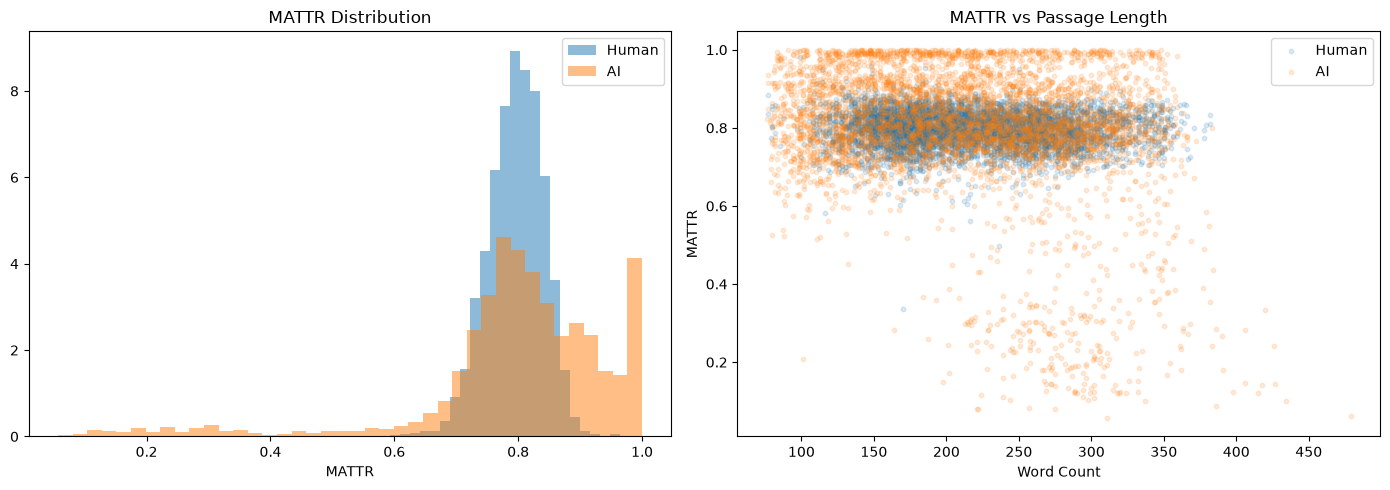

MATTR quantiles by class:


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
label,,,,,,,,,
0,0.3352,0.6840,0.7212,0.7674,0.7984,0.8275,0.8627,0.8856,0.9808
1,0.0569,0.1649,0.4520,0.7547,0.8120,0.8958,0.9904,0.9991,1.0000


In [45]:

# Compare MATTR distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, name in [(0, "Human"), (1, "AI")]:
    subset = features[features["label"] == label]

    axes[0].hist(
        subset["mattr"],
        bins=40,
        alpha=0.5,
        density=True,
        label=name
    )

    axes[1].scatter(
        subset["word_count"],
        subset["mattr"],
        alpha=0.15,
        s=10,
        label=name
    )

axes[0].set_title("MATTR Distribution")
axes[0].set_xlabel("MATTR")
axes[0].legend()

axes[1].set_title("MATTR vs Passage Length")
axes[1].set_xlabel("Word Count")
axes[1].set_ylabel("MATTR")
axes[1].legend()

plt.tight_layout()
plt.show()

# Investigate extreme values
print("MATTR quantiles by class:")

display(
    features.groupby("label")["mattr"]
    .quantile([0, .01, .05, .25, .50, .75, .95, .99, 1])
    .unstack()
    .round(4)
)


Experiment : Length of the passage plays a very important role in determinig, if it AI generated, splitting the passage based on characters.

In [46]:

# Create passage-length groups

features["length_group"] = pd.cut(
    features["word_count"],
    bins=[0, 100, 150, 200, 250, 300, 400],
    labels=["0-100", "100-150", "150-200",
            "200-250", "250-300", "300-400"]
)

length_analysis = features.groupby(
    ["length_group", "label"],
    observed=True
).agg(
    samples=("mattr", "count"),
    mean_mattr=("mattr", "mean"),
    mean_unique_ratio=("unique_word_ratio", "mean")
).round(4)

display(length_analysis)


samples  mean_mattr  mean_unique_ratio
length_group label                                        
0-100        0           16      0.8233             0.7447
             1          229      0.8205             0.7343
100-150      0          554      0.8013             0.6529
             1          919      0.8319             0.7109
150-200      0         1673      0.7973             0.6137
             1         1030      0.8390             0.6810
200-250      0         1315      0.7963             0.5746
             1         1088      0.8073             0.6204
250-300      0         1042      0.7893             0.5378
             1         1051      0.7561             0.5472
300-400      0          400      0.7988             0.5289
             1          674      0.7417             0.5105

In [47]:

audit = train[["id", "label"]].copy()

audit["id_group"] = pd.qcut(
    audit["id"].rank(method="first"),
    q=10,
    labels=False
)

print("AI proportion across ID groups:")

display(
    audit.groupby("id_group", observed=True)["label"]
    .agg(["mean", "count"])
)

print(
    "\nID-label correlation:",
    round(audit["id"].corr(audit["label"]), 5)
)


AI proportion across ID groups:


,mean,count
id_group,,
0,0.504,1000
1,0.531,1000
2,0.498,1000
3,0.502,1000
4,0.503,1000
5,0.474,1000
6,0.493,1000
7,0.474,1000
8,0.514,1000



ID-label correlation: -0.00937


Combining the original features with MATTR and length group, we can create a new feature matrix for modeling.

In [48]:

from sklearn.metrics import roc_auc_score
from scipy.stats import ks_2samp

# Define passage length groups
bins = [0, 100, 150, 200, 250, 300, 400]
labels = ["0-100", "100-150", "150-200",
          "200-250", "250-300", "300-400"]

features["length_group"] = pd.cut(
    features["word_count"],
    bins=bins,
    labels=labels
)

results = []

for group in labels:

    subset = features[
        features["length_group"] == group
    ]

    y_group = subset["label"]

    if y_group.nunique() < 2:
        continue

    for feature in [
        "unique_word_ratio",
        "mattr",
        "sentence_length_std"
    ]:

        auc = roc_auc_score(
            y_group,
            subset[feature]
        )

        human = subset.loc[
            y_group == 0, feature
        ]

        ai = subset.loc[
            y_group == 1, feature
        ]

        results.append({
            "Length": group,
            "Feature": feature,
            "AUROC": auc,
            "Oriented AUROC": max(auc, 1-auc),
            "Human Mean": human.mean(),
            "AI Mean": ai.mean(),
            "Sample Count": len(subset)
        })

conditional_results = pd.DataFrame(results)

display(
    conditional_results.round(4)
)


,Length,Feature,AUROC,Oriented AUROC,Human Mean,AI Mean,Sample Count
0,0-100,unique_word_ratio,0.4648,0.5352,0.7447,0.7343,245
1,0-100,mattr,0.5019,0.5019,0.8233,0.8205,245
2,0-100,sentence_length_std,0.4731,0.5269,6.9536,6.6507,245
3,100-150,unique_word_ratio,0.5989,0.5989,0.6529,0.7109,1473
4,100-150,mattr,0.5911,0.5911,0.8013,0.8319,1473
5,100-150,sentence_length_std,0.4647,0.5353,8.4437,8.7537,1473
6,150-200,unique_word_ratio,0.6135,0.6135,0.6137,0.6810,2703
7,150-200,mattr,0.6464,0.6464,0.7973,0.8390,2703
8,150-200,sentence_length_std,0.4867,0.5133,9.5541,10.9444,2703
9,200-250,unique_word_ratio,0.5654,0.5654,0.5746,0.6204,2403


In [49]:

def lexical_profile(text):
    words = re.findall(r"\b\w+\b", str(text).lower())

    result = {}

    for window_size in [25, 50, 75]:

        if len(words) < window_size:
            values = [
                len(set(words)) / max(len(words), 1)
            ]
        else:
            values = [
                len(set(words[i:i + window_size])) / window_size
                for i in range(len(words) - window_size + 1)
            ]

        result[f"mattr_{window_size}"] = np.mean(values)
        result[f"mattr_{window_size}_std"] = np.std(values)
        result[f"mattr_{window_size}_min"] = np.min(values)
        result[f"mattr_{window_size}_max"] = np.max(values)

    return result


lexical_features = pd.DataFrame(
    train["text"].fillna("").apply(lexical_profile).tolist()
)

print("New lexical feature matrix:", lexical_features.shape)

display(
    lexical_features.groupby(train["label"]).mean().round(4)
)


New lexical feature matrix: (10000, 12)


,mattr_25,mattr_25_std,mattr_25_min,mattr_25_max,mattr_50,mattr_50_std,mattr_50_min,mattr_50_max,mattr_75,mattr_75_std,mattr_75_min,mattr_75_max
label,,,,,,,,,,,,
0,0.8832,0.0621,0.7228,0.9914,0.7960,0.0499,0.6855,0.8931,0.7381,0.0386,0.6589,0.8116
1,0.8772,0.0577,0.7383,0.9767,0.7982,0.0479,0.7013,0.8906,0.7474,0.0378,0.6762,0.8192


Checking in terms of window size

In [50]:

# ==========================================
# EXPERIMENT 09: LENGTH-CONDITIONED FEATURES
# ==========================================

from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Keep numeric features only
X_base = features.drop(
    columns=["label", "length_group"],
    errors="ignore"
).select_dtypes(include=[np.number]).copy()

y = features["label"]

# Normalize length for interaction calculations
length_scaled = (
    X_base["word_count"] - X_base["word_count"].median()
) / max(X_base["word_count"].std(), 1)

# Create experimental interaction features
X_interaction = X_base.copy()

for col in [
    "unique_word_ratio",
    "mattr",
    "sentence_length_std"
]:
    X_interaction[f"{col}_x_length"] = (
        X_base[col] * length_scaled
    )

# Add length-region indicators
length_bins = pd.cut(
    X_base["word_count"],
    bins=[0, 100, 150, 200, 250, 300, 400],
    labels=False
)

length_dummies = pd.get_dummies(
    length_bins,
    prefix="length_bin",
    dtype=int
)

X_interaction = pd.concat(
    [X_interaction, length_dummies],
    axis=1
)

# Cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def evaluate_rf(X, y):
    model = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("rf", RandomForestClassifier(
            n_estimators=500,
            max_depth=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        ))
    ])

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    return scores

# Compare architectures
experiments = {
    "Base features": X_base,
    "Length interactions": X_interaction
}

for name, X_exp in experiments.items():
    scores = evaluate_rf(X_exp, y)

    print(
        f"{name}: {scores.mean():.5f} "
        f"+/- {scores.std():.5f}"
    )

    print("Fold scores:", np.round(scores, 4))


Base features: 0.89024 +/- 0.00701
Fold scores: [0.8774 0.8886 0.8924 0.8959 0.8968]
Length interactions: 0.88906 +/- 0.00617
Fold scores: [0.8781 0.8897 0.888  0.8932 0.8963]


Retraining Random Forest Model based on length groups

In [51]:

from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Use all current numeric features
X = features.drop(
    columns=["label", "length_group"],
    errors="ignore"
).select_dtypes(include=[np.number])

y = features["label"]

# Preserve original row indices
train_idx, val_idx = train_test_split(
    np.arange(len(train)),
    test_size=0.20,
    stratify=y,
    random_state=42
)

X_train = X.iloc[train_idx]
X_val = X.iloc[val_idx]

y_train = y.iloc[train_idx]
y_val = y.iloc[val_idx]

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("rf", RandomForestClassifier(
        n_estimators=500,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

val_probs = model.predict_proba(X_val)[:, 1]

print("Validation AUROC:",
      round(roc_auc_score(y_val, val_probs), 5))


Validation AUROC: 0.88776


In [52]:

# Construct validation predictions
errors = pd.DataFrame({
    "original_index": val_idx,
    "actual": y_val.values,
    "predicted_probability": val_probs
})

errors["predicted"] = (
    errors["predicted_probability"] >= 0.5
).astype(int)

# Incorrect predictions
errors["incorrect"] = (
    errors["actual"] != errors["predicted"]
)

# Confidence in the incorrect prediction
errors["error_confidence"] = np.where(
    errors["actual"] == 0,
    errors["predicted_probability"],
    1 - errors["predicted_probability"]
)

misclassified = errors[errors["incorrect"]].copy()

print("Total validation errors:", len(misclassified))

# False positives: Human classified as AI
false_positives = misclassified[
    misclassified["actual"] == 0
].sort_values("error_confidence", ascending=False)

# False negatives: AI classified as Human
false_negatives = misclassified[
    misclassified["actual"] == 1
].sort_values("error_confidence", ascending=False)

print("\nFalse positives:", len(false_positives))
print("False negatives:", len(false_negatives))


Total validation errors: 391

False positives: 129
False negatives: 262


In [53]:

def inspect_errors(error_df, title, n=5):
    print("\n" + "=" * 70)
    print(title)
    print("=" * 70)

    for _, row in error_df.head(n).iterrows():

        idx = int(row["original_index"])
        text = train.iloc[idx]["text"]

        print("\nActual label:",
              row["actual"])

        print("Predicted AI probability:",
              round(row["predicted_probability"], 4))

        print("Word count:",
              len(str(text).split()))

        print("\n", str(text)[:1200])
        print("-" * 70)


inspect_errors(
    false_positives,
    "HUMAN TEXT INCORRECTLY CLASSIFIED AS AI"
)

inspect_errors(
    false_negatives,
    "AI TEXT INCORRECTLY CLASSIFIED AS HUMAN"
)



HUMAN TEXT INCORRECTLY CLASSIFIED AS AI

Actual label: 0
Predicted AI probability: 0.9385
Word count: 240

 4 cups kale (about 1 bunch)
1 yellow onion, finely chopped
2 tablespoons olive oil or sunflower oil
4 eggs
1 1/2 cups feta cheese, crumbled
2 tablespoons Parmesan cheese, freshly grated
1 teaspoon black pepper, freshly grated
1/2 cup unsalted butter, melted
phyllo pastry
In a medium pan over medium heat, saute the onion in olive oil until translucent. Add the kale to the onion and turn the heat down to low. Cover and let it cook for a few minutes or until the kale starts to wilt. Remove from heat and allow to cool. Preheat the oven to 190C. In a large mixing bowl, add the eggs, flour, and baking powder. Give it a whisk. Season with freshly grated nutmeg, black pepper and Parmesan cheese. Add the toasted walnuts, crumbled feta cheese and sauteed kale with onion. Combine everything well together. Line a baking pan with parchment baking paper. Start assembling the kale triangles: P

In [54]:

# ==========================================
# EXPERIMENT 10A: ERROR PATTERN ANALYSIS
# ==========================================

error_analysis = misclassified.copy()

# Attach original passage and extracted features
error_analysis["text"] = train.iloc[
    error_analysis["original_index"]
]["text"].values

error_analysis["word_count"] = features.iloc[
    error_analysis["original_index"]
]["word_count"].values

error_analysis["unique_word_ratio"] = features.iloc[
    error_analysis["original_index"]
]["unique_word_ratio"].values

error_analysis["sentence_length_std"] = features.iloc[
    error_analysis["original_index"]
]["sentence_length_std"].values

error_analysis["error_type"] = np.where(
    error_analysis["actual"] == 0,
    "False Positive",
    "False Negative"
)

# Passage length analysis
error_analysis["length_group"] = pd.cut(
    error_analysis["word_count"],
    bins=[0, 100, 150, 200, 250, 300, 400, 1000]
)

print("ERROR DISTRIBUTION BY LENGTH")

display(
    error_analysis.groupby(
        ["length_group", "error_type"],
        observed=True
    ).size().unstack(fill_value=0)
)

# Compare correctly classified and incorrectly classified samples
print("\nFEATURE COMPARISON")

error_analysis["correct"] = (
    error_analysis["actual"] == error_analysis["predicted"]
)

display(
    error_analysis.groupby("error_type")[
        ["word_count", "unique_word_ratio",
         "sentence_length_std"]
    ].mean().round(4)
)

# Confidence distribution
print("\nERROR CONFIDENCE")

display(
    error_analysis.groupby("error_type")[
        "error_confidence"
    ].describe().round(4)
)


ERROR DISTRIBUTION BY LENGTH


error_type,False Negative,False Positive
length_group,,
"(0, 100]",0,3
"(100, 150]",35,24
"(150, 200]",69,23
"(200, 250]",64,32
"(250, 300]",64,32
"(300, 400]",30,15



FEATURE COMPARISON


,word_count,unique_word_ratio,sentence_length_std
error_type,,,
False Negative,223.6145,0.5799,9.9804
False Positive,217.4806,0.5843,7.4972



ERROR CONFIDENCE


,count,mean,std,min,25%,50%,75%,max
error_type,,,,,,,,
False Negative,262.0,0.6618,0.0951,0.5003,0.5790,0.6529,0.7459,0.8568
False Positive,129.0,0.6251,0.1002,0.5015,0.5439,0.5970,0.6776,0.9385


In [55]:

# Show 20 most confidently misclassified passages

for _, row in misclassified.sort_values(
    "error_confidence",
    ascending=False
).head(20).iterrows():

    idx = int(row["original_index"])

    print("\n" + "=" * 70)
    print("ACTUAL:", "AI" if row["actual"] == 1 else "HUMAN")
    print("PREDICTED:", "AI" if row["predicted"] == 1 else "HUMAN")
    print("AI PROBABILITY:", round(row["predicted_probability"], 4))
    print("WORDS:", len(str(train.iloc[idx]["text"]).split()))

    print(str(train.iloc[idx]["text"])[:500])



ACTUAL: HUMAN
PREDICTED: AI
AI PROBABILITY: 0.9385
WORDS: 240
4 cups kale (about 1 bunch)
1 yellow onion, finely chopped
2 tablespoons olive oil or sunflower oil
4 eggs
1 1/2 cups feta cheese, crumbled
2 tablespoons Parmesan cheese, freshly grated
1 teaspoon black pepper, freshly grated
1/2 cup unsalted butter, melted
phyllo pastry
In a medium pan over medium heat, saute the onion in olive oil until translucent. Add the kale to the onion and turn the heat down to low. Cover and let it cook for a few minutes or until the kale starts to wilt. Remove from hea

ACTUAL: HUMAN
PREDICTED: AI
AI PROBABILITY: 0.9212
WORDS: 134
I'm usually pretty cynical about cheesy movies but this movie absolutely floored me.  Drew Barrymore was phenomenal playing role of Julia Sullivan. I've seen the movie at least 30 times by now and her expressions still make me cry, they're just so sincere. I don't know how else to put it.  As for Adam Sandler I think that this is his best role yet, he's a real person in 

In [56]:

# ==========================================
# EXPERIMENT 11: CLASS-CONDITIONED ERROR ANALYSIS
# ==========================================

# Use ALL validation predictions, not just errors
analysis_df = errors.copy()

# Attach original features
idx = analysis_df["original_index"].astype(int)

for col in [
    "word_count",
    "unique_word_ratio",
    "sentence_length_std",
    "mattr",
    "avg_word_length",
    "avg_sentence_length"
]:
    if col in features.columns:
        analysis_df[col] = features.iloc[idx][col].values

analysis_df["status"] = np.where(
    analysis_df["incorrect"],
    "Incorrect",
    "Correct"
)

# Compare within each actual class
print("AI PASSAGES: CORRECT VS MISSED")

display(
    analysis_df[analysis_df["actual"] == 1]
    .groupby("status")[
        ["word_count", "unique_word_ratio",
         "sentence_length_std", "mattr"]
    ]
    .agg(["mean", "median", "std"])
    .round(4)
)

print("\nHUMAN PASSAGES: CORRECT VS FALSE ALARMS")

display(
    analysis_df[analysis_df["actual"] == 0]
    .groupby("status")[
        ["word_count", "unique_word_ratio",
         "sentence_length_std", "mattr"]
    ]
    .agg(["mean", "median", "std"])
    .round(4)
)


AI PASSAGES: CORRECT VS MISSED


word_count                 unique_word_ratio                  \
                mean median      std              mean  median     std   
status                                                                   
Correct     209.4675  211.5  75.1386            0.6447  0.6508  0.2213   
Incorrect   223.6145  217.0  59.7361            0.5799  0.5743  0.0696   

          sentence_length_std                    mattr                  
                         mean  median      std    mean  median     std  
status                                                                  
Correct               12.4534  7.5999  16.0385  0.8076  0.8269  0.1674  
Incorrect              9.9804  7.9657   6.3709  0.7946  0.7970  0.0456


HUMAN PASSAGES: CORRECT VS FALSE ALARMS


word_count                 unique_word_ratio                  \
                mean median      std              mean  median     std   
status                                                                   
Correct     214.3904  208.0  55.3567            0.5871  0.5879  0.0634   
Incorrect   217.4806  225.0  68.6939            0.5843  0.5783  0.1021   

          sentence_length_std                   mattr                  
                         mean  median     std    mean  median     std  
status                                                                 
Correct               10.4325  9.3571  4.9406  0.7966  0.7995  0.0407  
Incorrect              7.4972  6.2890  4.1862  0.7937  0.8002  0.0661

In [57]:
import pandas as pd
import numpy as np

# Create length groups in the analysis dataframe
analysis_df["length_group"] = pd.cut(
    analysis_df["word_count"],
    bins=[0, 100, 150, 200, 250, 300, 400],
    labels=[
        "0-100",
        "100-150",
        "150-200",
        "200-250",
        "250-300",
        "300-400"
    ],
    include_lowest=True
)

# Calculate total passages and errors per length group and true class
length_error_rates = (
    analysis_df
    .groupby(["length_group", "actual"], observed=True)
    .agg(
        total=("incorrect", "size"),
        errors=("incorrect", "sum")
    )
    .reset_index()
)

length_error_rates["error_rate"] = (
    length_error_rates["errors"] /
    length_error_rates["total"]
)

length_error_rates["actual_class"] = (
    length_error_rates["actual"]
    .map({0: "Human", 1: "AI"})
)

display(
    length_error_rates[
        ["length_group", "actual_class", "total", "errors", "error_rate"]
    ]
)

,length_group,actual_class,total,errors,error_rate
0,0-100,Human,3,3,1.000000
1,0-100,AI,45,0,0.000000
2,100-150,Human,119,24,0.201681
3,100-150,AI,191,35,0.183246
4,150-200,Human,333,23,0.069069
5,150-200,AI,205,69,0.336585
6,200-250,Human,277,32,0.115523
7,200-250,AI,223,64,0.286996
8,250-300,Human,183,32,0.174863
9,250-300,AI,206,64,0.310680


In [58]:
from scipy.stats import mannwhitneyu

features_to_test = [
    "word_count",
    "unique_word_ratio",
    "sentence_length_std",
    "mattr"
]

for actual_class, class_name in [(1, "AI"), (0, "Human")]:
    subset = analysis_df[analysis_df["actual"] == actual_class]

    print(f"\n--- {class_name} PASSAGES ---")

    for feature in features_to_test:
        correct = subset.loc[
            ~subset["incorrect"], feature
        ].dropna()

        incorrect = subset.loc[
            subset["incorrect"], feature
        ].dropna()

        statistic, p_value = mannwhitneyu(
            correct, incorrect, alternative="two-sided"
        )

        print(
            f"{feature}: "
            f"Correct={correct.median():.4f}, "
            f"Incorrect={incorrect.median():.4f}, "
            f"p={p_value:.6f}"
        )


--- AI PASSAGES ---
word_count: Correct=211.5000, Incorrect=217.0000, p=0.005112
unique_word_ratio: Correct=0.6508, Incorrect=0.5743, p=0.000000
sentence_length_std: Correct=7.5999, Incorrect=7.9657, p=0.049533
mattr: Correct=0.8269, Incorrect=0.7970, p=0.000000

--- Human PASSAGES ---
word_count: Correct=208.0000, Incorrect=225.0000, p=0.372265
unique_word_ratio: Correct=0.5879, Incorrect=0.5783, p=0.697738
sentence_length_std: Correct=9.3571, Incorrect=6.2890, p=0.000000
mattr: Correct=0.7995, Incorrect=0.8002, p=0.941153


In [59]:
# Focus on AI passages between 150 and 200 words

ai_mid = analysis_df[
    (analysis_df["actual"] == 1) &
    (analysis_df["word_count"] > 150) &
    (analysis_df["word_count"] <= 200)
].copy()

print("AI passages in this range:", len(ai_mid))

comparison = ai_mid.groupby("incorrect").agg(
    count=("word_count", "size"),
    word_count=("word_count", "mean"),
    unique_word_ratio=("unique_word_ratio", "mean"),
    sentence_length_std=("sentence_length_std", "mean"),
    mattr=("mattr", "mean")
)

comparison.index = ["Correctly detected", "Missed by model"]

display(comparison)

AI passages in this range: 205


,count,word_count,unique_word_ratio,sentence_length_std,mattr
Correctly detected,136,175.176471,0.707045,11.658341,0.851318
Missed by model,69,178.014493,0.593243,8.689015,0.793202


In [60]:
import re
import numpy as np
import pandas as pd

def segment_lexical_features(text):
    words = re.findall(r"\b\w+\b", str(text).lower())

    if len(words) < 30:
        return {
            "first_third_ttr": np.nan,
            "middle_third_ttr": np.nan,
            "last_third_ttr": np.nan,
            "lexical_diversity_change": np.nan
        }

    third = len(words) // 3

    first = words[:third]
    middle = words[third:2*third]
    last = words[2*third:]

    def ttr(segment):
        return len(set(segment)) / max(len(segment), 1)

    first_ttr = ttr(first)
    middle_ttr = ttr(middle)
    last_ttr = ttr(last)

    return {
        "first_third_ttr": first_ttr,
        "middle_third_ttr": middle_ttr,
        "last_third_ttr": last_ttr,
        "lexical_diversity_change": last_ttr - first_ttr
    }


segment_features = pd.DataFrame(
    train["text"].apply(segment_lexical_features).tolist()
)

analysis_df = analysis_df.join(
    segment_features.loc[analysis_df.index]
)

display(
    analysis_df[
        (analysis_df["actual"] == 1) &
        (analysis_df["word_count"] > 150) &
        (analysis_df["word_count"] <= 200)
    ].groupby("incorrect").agg({
        "first_third_ttr": "mean",
        "middle_third_ttr": "mean",
        "last_third_ttr": "mean",
        "lexical_diversity_change": "mean"
    })
)

,first_third_ttr,middle_third_ttr,last_third_ttr,lexical_diversity_change
incorrect,,,,
False,0.752428,0.743027,0.754696,0.002268
True,0.747420,0.741858,0.754084,0.006664


In [61]:
from collections import Counter
import re
import numpy as np
import pandas as pd

def repetition_features(text):
    words = re.findall(r"\b\w+\b", str(text).lower())

    def repetition_rate(n):
        if len(words) < n:
            return 0

        ngrams = [
            tuple(words[i:i+n])
            for i in range(len(words)-n+1)
        ]

        counts = Counter(ngrams)

        # Proportion of n-gram occurrences belonging to
        # n-grams that appear more than once
        repeated = sum(
            count for count in counts.values()
            if count > 1
        )

        return repeated / len(ngrams)

    return {
        "bigram_repetition": repetition_rate(2),
        "trigram_repetition": repetition_rate(3)
    }


repetition_df = pd.DataFrame(
    train["text"].apply(repetition_features).tolist()
)

analysis_df = analysis_df.join(
    repetition_df.loc[analysis_df.index]
)

ai_mid = analysis_df[
    (analysis_df["actual"] == 1) &
    (analysis_df["word_count"] > 150) &
    (analysis_df["word_count"] <= 200)
]

display(
    ai_mid.groupby("incorrect").agg({
        "bigram_repetition": ["mean", "median"],
        "trigram_repetition": ["mean", "median"]
    })
)

bigram_repetition           trigram_repetition          
                       mean    median               mean    median
incorrect                                                         
False              0.174550  0.135529           0.083940  0.034929
True               0.183601  0.142241           0.089338  0.033003

In [62]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np

# Existing numeric features
X_base = (
    features
    .drop(columns=["label", "length_group"], errors="ignore")
    .select_dtypes(include=np.number)
    .copy()
)

# Add the two repetition features
X_repetition = X_base.join(
    repetition_df[["bigram_repetition", "trigram_repetition"]]
)

y = train["label"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def evaluate_features(X, name):
    model = RandomForestClassifier(
        n_estimators=400,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model, X, y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    print(
        f"{name}: {scores.mean():.6f} "
        f"+/- {scores.std():.6f}"
    )

    return scores

base_scores = evaluate_features(X_base, "Baseline")
repetition_scores = evaluate_features(
    X_repetition, "Baseline + repetition"
)

print(
    "Fold-wise improvement:",
    np.round(repetition_scores - base_scores, 6)
)

Baseline: 0.890091 +/- 0.006924
Baseline + repetition: 0.897601 +/- 0.009357
Fold-wise improvement: [0.004255 0.004884 0.007407 0.010836 0.010166]


In [63]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

y = train["label"]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

feature_sets = {
    "Baseline": X_base,
    "Baseline + Bigram": X_base.join(
        repetition_df[["bigram_repetition"]]
    ),
    "Baseline + Trigram": X_base.join(
        repetition_df[["trigram_repetition"]]
    ),
    "Baseline + Both": X_base.join(
        repetition_df[[
            "bigram_repetition",
            "trigram_repetition"
        ]]
    )
}

results = {}

for name, X in feature_sets.items():
    model = RandomForestClassifier(
        n_estimators=400,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    scores = cross_val_score(
        model,
        X,
        y,
        cv=cv,
        scoring="roc_auc",
        n_jobs=-1
    )

    results[name] = scores

comparison = pd.DataFrame({
    name: {
        "mean_AUROC": scores.mean(),
        "std_AUROC": scores.std()
    }
    for name, scores in results.items()
}).T.sort_values("mean_AUROC", ascending=False)

display(comparison.round(6))

,mean_AUROC,std_AUROC
Baseline + Trigram,0.898947,0.008799
Baseline + Both,0.897601,0.009357
Baseline + Bigram,0.896288,0.009975
Baseline,0.890091,0.006924
